# Logistic regression: which tracks should we push?
**Question:** Which features make a hit more likely, and what cut-off should we use to decide which tracks to push?

The OLS model (`regression-fit.ipynb`) predicts a popularity *score*. A label's actual decision is yes/no: push a track or not. This notebook models that decision directly:
- the target is `hit` (1 = top 10% of popularity, 0 = otherwise)
- the output is a **probability of being a hit per song**, plus **odds ratios** showing which features raise or lower the odds
- the decision rule is **"push tracks whose predicted hit probability is above X%"**, with X chosen on training data and checked on unseen artists

Run `bt4211-project.ipynb` first; it saves `tracks_clean.pkl`. Run `regression-fit.ipynb` first too if you want the OLS comparison in section 4.

# 1) Imports and data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from IPython.display import display
SEED = 42
Path("figures").mkdir(exist_ok=True); Path("outputs").mkdir(exist_ok=True)
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "axes.titleweight": "bold", "figure.dpi": 110})

tracks = pd.read_pickle("tracks_clean.pkl")
tracks["artist"] = tracks["artists"].str.split(";").str[0].str.strip()
tracks["track_index"] = tracks.index    # row key into the genre weights below
print(f"{len(tracks):,} songs")

81,343 songs


# 2) Defining a hit
- **Popularity-0 songs are left out**, as in the OLS model: they are mostly a collection artefact (EDA E1, E4). Section 7 checks what happens if they are kept.
- **Same train/test split as OLS:** 80/20 by artist with the same seed, so the test set is the same unseen artists and the two models can be compared song for song.
- **Hit = popularity at or above the 90th percentile of the *training* set.** Taking the cut-off from training data only keeps the test set untouched. Top 10% is a judgement call (a label can only push a small share of its catalogue), so section 7 repeats the analysis with top 5% and top 20%.

hit = popularity >= 61


,songs,hits,hit_rate
in_test_set,,,
train,61513,6732,0.109
test,15072,1731,0.115


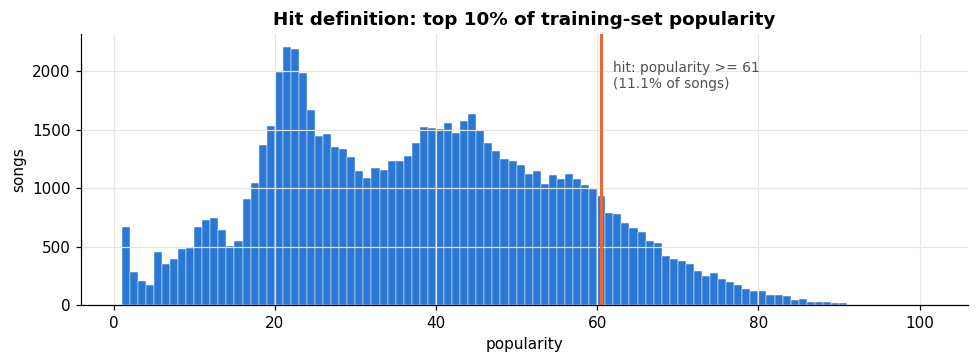

In [2]:
def split(df):
    tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["artist"]))
    return df.index.isin(df.index[te_i])

t = tracks[tracks["popularity"] > 0].reset_index(drop=True).copy()
t["in_test_set"] = split(t)
HIT_Q = 0.90
HIT_THR = t.loc[~t["in_test_set"], "popularity"].quantile(HIT_Q)
t["hit"] = (t["popularity"] >= HIT_THR).astype(int)
print(f"hit = popularity >= {HIT_THR:.0f}")
display(t.groupby("in_test_set")["hit"].agg(songs="size", hits="sum", hit_rate="mean")
          .rename(index={False: "train", True: "test"}).round(3))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(t["popularity"], bins=range(1, 102), color=BLUE, edgecolor="#fcfcfb", linewidth=0.3)
ax.axvline(HIT_THR - 0.5, color=ORANGE, lw=2)
ax.text(HIT_THR + 1, ax.get_ylim()[1] * 0.9, f"hit: popularity >= {HIT_THR:.0f}\n({t['hit'].mean():.1%} of songs)", color=MUTED, fontsize=9, va="top")
ax.set_xlabel("popularity"); ax.set_ylabel("songs"); ax.set_title("Hit definition: top 10% of training-set popularity")
fig.tight_layout(); plt.savefig("figures/logit_01_hit_definition.png", dpi=150, bbox_inches="tight"); plt.show()

Ties at the cut-off push the hit rate slightly above 10%. With roughly 1 hit for every 8 non-hits, accuracy is a misleading score: predicting "no hit" for every song is already ~89% accurate. Models are therefore judged on **ROC AUC** (ranking), **average precision** (precision across the ranking, against the hit rate as baseline) and the **Brier score** (how accurate the probabilities are).

# 3) Features
Same features as the OLS model, so the two are comparable:
- $\log_2$ for the skewed features (duration capped at p99.5, speechiness, liveness), and flags for explicit, collaboration, 4/4 time and non-music
- the same three squared terms and three interactions
- genre as fractional multi-hot weights, with `pop` as the reference

Two changes:
- **Scaling and the duration cap are fitted on the training set only**, so nothing about the test songs leaks into the features.
- **Genres with fewer than 10 training hits are pooled** into one `g_low_hit_pool` weight. Several genres (e.g. study, grindcore, detroit-techno) have no hits at all. For those, the logistic coefficient goes to minus infinity (perfect separation) and the fit fails. Pooling keeps every song and states the honest finding: "these genres almost never produce hits". Section 7 checks the pooling against a penalised model that keeps every genre separate.
- The k-means sound clusters are dropped. They added only 0.002 test $R^2$ in the OLS model, and they are built from the audio features the model already has.

In [3]:
AUDIO = ["danceability", "energy", "loudness", "log_speechiness", "acousticness",
         "instrumentalness", "log_liveness", "valence", "tempo", "log_duration"]
GENRE_W = pd.get_dummies(tracks["genres"].explode().replace({"songwriter": "singer-songwriter"})).groupby(level=0).max().astype(float)
GENRE_W.columns = ["g_" + c.replace("-", "_") for c in GENRE_W.columns]
GENRE_W = GENRE_W.div(GENRE_W.sum(axis=1), axis=0)   # fractional weights, indexed like `tracks`

def build_features(df, min_hits=10):
    # fit every transform on the training rows only
    df = df.copy()
    tr = ~df["in_test_set"]
    df["log_duration"] = np.log2(df["duration_min"].clip(upper=df.loc[tr, "duration_min"].quantile(0.995)))
    df["log_speechiness"] = np.log2(df["speechiness"] + 0.01)
    df["log_liveness"] = np.log2(df["liveness"] + 0.01)
    df["tempo"] = df["tempo"].fillna(df.loc[tr, "tempo"].median())    # undefined only for non_music tracks
    df["is_4_4"] = df["time_signature"].eq(4).fillna(False).astype(int)
    for c in ["explicit", "collab", "non_music"]:
        df[c] = df[c].astype(int)
    mu, sd = df.loc[tr, AUDIO].mean(), df.loc[tr, AUDIO].std()
    for c in AUDIO:
        df["z_" + c] = (df[c] - mu[c]) / sd[c]

    W = GENRE_W.loc[df["track_index"]].reset_index(drop=True)
    pooled = []
    if min_hits:
        hits = (W[tr.values] > 0).mul(df.loc[tr, "hit"].values, axis=0).sum()
        pooled = [g for g in hits[hits < min_hits].index if g != "g_pop"]
        W["g_low_hit_pool"] = W[pooled].sum(axis=1)
        W = W.drop(columns=pooled)
    df = pd.concat([df.reset_index(drop=True), W], axis=1)
    return df, [c for c in W.columns if c != "g_pop"], pooled

t, GENRES, POOLED = build_features(t)
print(f"{len(AUDIO)} audio features, {len(GENRES)} genre terms (reference: pop)")
print(f"{len(POOLED)} genres pooled into g_low_hit_pool: {', '.join(g[2:] for g in POOLED)}")

10 audio features, 75 genre terms (reference: pop)
38 genres pooled into g_low_hit_pool: afrobeat, black_metal, bluegrass, brazil, breakbeat, cantopop, chicago_house, club, comedy, death_metal, detroit_techno, drum_and_bass, forro, gospel, goth, grindcore, guitar, happy, heavy_metal, honky_tonk, idm, iranian, j_idol, kids, malay, minimal_techno, mpb, new_age, opera, pagode, party, romance, salsa, samba, sertanejo, ska, study, tango


# 4) Model fitting
The models are built up in blocks, as in the OLS notebook, so each row shows what one block adds. Standard errors are clustered by artist. Two reference points:
- **Genre only:** how far genre alone gets.
- **OLS ranking:** the OLS model's predicted popularity used as a hit score (from `outputs/ols_predictions.csv`, same test songs). This tests whether modelling the yes/no decision directly beats ranking by a predicted score.

In [4]:
BASE = " + ".join("z_" + c for c in AUDIO) + " + explicit + collab + is_4_4 + non_music"
SQ = " + I(z_danceability**2) + I(z_acousticness**2) + I(z_log_duration**2)"
INTER = " + z_danceability:z_valence + z_energy:z_acousticness + explicit:z_danceability"
GENRE = " + " + " + ".join(GENRES)
FORMULAS = {
    "1. audio + flags": "hit ~ " + BASE,
    "2. + squares + interactions": "hit ~ " + BASE + SQ + INTER,
    "genre only": "hit ~ " + " + ".join(GENRES),
    "3. + genre (final)": "hit ~ " + BASE + SQ + INTER + GENRE,
}
train, test = t[~t["in_test_set"]], t[t["in_test_set"]]

def fit_logit(f, df, robust=True):
    kw = {"cov_type": "cluster", "cov_kwds": {"groups": pd.factorize(df["artist"])[0]}} if robust else {}
    return smf.logit(f, df).fit(disp=0, maxiter=200, **kw)

def scores(y, p):
    return {"test_AUC": roc_auc_score(y, p), "test_avg_precision": average_precision_score(y, p),
            "test_Brier": brier_score_loss(y, p), "test_log_loss": log_loss(y, p)}

fits, rows = {}, []
for name, f in FORMULAS.items():
    res = fit_logit(f, train)
    assert res.mle_retvals["converged"], name
    fits[name] = res
    rows.append({"model": name, "params": len(res.params), "train_pseudo_R2": res.prsquared, **scores(test["hit"], res.predict(test))})

ols_path = Path("outputs/ols_predictions.csv")
if ols_path.exists():
    ols = test[["track_id"]].merge(pd.read_csv(ols_path), on="track_id", how="left")
    assert ols["in_test_set"].all(), "OLS test set differs; re-run regression-fit.ipynb"
    rows.append({"model": "OLS predicted popularity (ranking only)",
                 "test_AUC": roc_auc_score(test["hit"], ols["predicted_popularity"]),
                 "test_avg_precision": average_precision_score(test["hit"], ols["predicted_popularity"])})
rows.append({"model": "no model (hit rate)", "test_avg_precision": test["hit"].mean(),
             "test_Brier": brier_score_loss(test["hit"], np.full(len(test), train["hit"].mean()))})
model_tbl = pd.DataFrame(rows).set_index("model")
display(model_tbl.round(4))
final = fits["3. + genre (final)"]

,params,train_pseudo_R2,test_AUC,test_avg_precision,test_Brier,test_log_loss
model,,,,,,
1. audio + flags,15.0,0.0479,0.6900,0.2183,0.0970,0.3338
2. + squares + interactions,21.0,0.0565,0.7037,0.2227,0.0964,0.3298
genre only,76.0,0.3492,0.8760,0.5080,0.0751,0.2461
3. + genre (final),96.0,0.3591,0.8850,0.5332,0.0734,0.2407
OLS predicted popularity (ranking only),NaN,NaN,0.8491,0.4715,NaN,NaN
no model (hit rate),NaN,NaN,NaN,0.1148,0.1017,NaN


# 5) Which features raise or lower the odds?
An **odds ratio** (OR) above 1 raises the odds of a hit and below 1 lowers them. For the standardised audio features, the OR is per 1 SD increase. For flags, it compares yes vs no. The 95% CIs use artist-clustered standard errors.

Danceability, acousticness and duration also have squared terms, so their main OR applies at the average value. Their full shape is in the effect curves below.

,odds_ratio,ci_low,ci_high,p
label,,,,
non-music,0.110,0.031,0.392,0.001
energy,0.816,0.746,0.892,0.000
acousticness,0.839,0.769,0.915,0.000
duration²,0.886,0.857,0.917,0.000
instrumentalness,0.899,0.834,0.969,0.005
energy × acousticness,0.900,0.835,0.969,0.005
acousticness²,0.906,0.837,0.980,0.014
collaboration,0.928,0.820,1.049,0.230
liveness (log),0.929,0.894,0.966,0.000


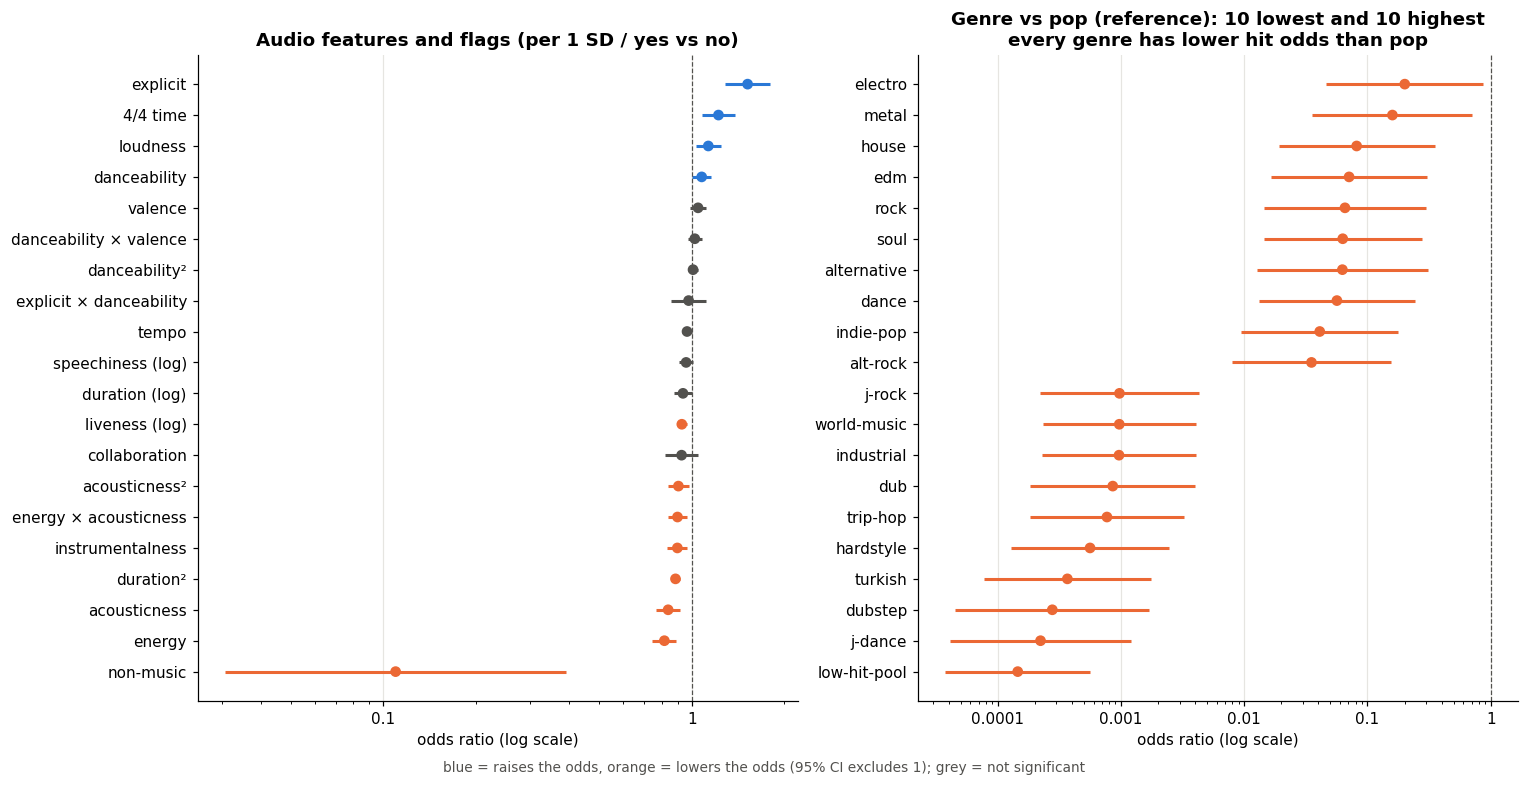

In [5]:
ci = np.exp(final.conf_int())
odds = pd.DataFrame({"coef": final.params, "odds_ratio": np.exp(final.params), "ci_low": ci[0], "ci_high": ci[1],
                     "p": final.pvalues}).rename_axis("term")
odds.to_csv("outputs/logit_odds_ratios.csv")

LABELS = {"z_danceability": "danceability", "z_energy": "energy", "z_loudness": "loudness",
          "z_log_speechiness": "speechiness (log)", "z_acousticness": "acousticness",
          "z_instrumentalness": "instrumentalness", "z_log_liveness": "liveness (log)", "z_valence": "valence",
          "z_tempo": "tempo", "z_log_duration": "duration (log)", "explicit": "explicit", "collab": "collaboration",
          "is_4_4": "4/4 time", "non_music": "non-music",
          "I(z_danceability ** 2)": "danceability²", "I(z_acousticness ** 2)": "acousticness²",
          "I(z_log_duration ** 2)": "duration²", "z_danceability:z_valence": "danceability × valence",
          "z_energy:z_acousticness": "energy × acousticness", "explicit:z_danceability": "explicit × danceability"}
feat = odds.loc[list(LABELS)].assign(label=lambda d: d.index.map(LABELS)).sort_values("odds_ratio")
display(feat.set_index("label")[["odds_ratio", "ci_low", "ci_high", "p"]].round(3))

def forest(ax, d, title):
    y = np.arange(len(d))
    sig = (d["ci_low"] > 1) | (d["ci_high"] < 1)
    colors = np.where(~sig, MUTED, np.where(d["odds_ratio"] > 1, BLUE, ORANGE))
    ax.hlines(y, d["ci_low"], d["ci_high"], color=colors, lw=2)
    ax.scatter(d["odds_ratio"], y, color=colors, s=36, zorder=3)
    ax.axvline(1, color=MUTED, lw=0.8, ls="--")
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%g"))
    ax.set_yticks(y); ax.set_yticklabels(d["label"]); ax.grid(axis="y", visible=False)
    ax.set_xlabel("odds ratio (log scale)"); ax.set_title(title)

genre_or = odds.loc[GENRES].assign(label=lambda d: d.index.str[2:].str.replace("_", "-"))
genre_show = pd.concat([genre_or.nsmallest(10, "odds_ratio"), genre_or.nlargest(10, "odds_ratio")]).sort_values("odds_ratio")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
forest(axes[0], feat, "Audio features and flags (per 1 SD / yes vs no)")
forest(axes[1], genre_show, "Genre vs pop (reference): 10 lowest and 10 highest\nevery genre has lower hit odds than pop")
fig.text(0.5, -0.01, "blue = raises the odds, orange = lowers the odds (95% CI excludes 1); grey = not significant",
         ha="center", color=MUTED, fontsize=9)
fig.tight_layout(); plt.savefig("figures/logit_02_odds_ratios.png", dpi=150, bbox_inches="tight"); plt.show()

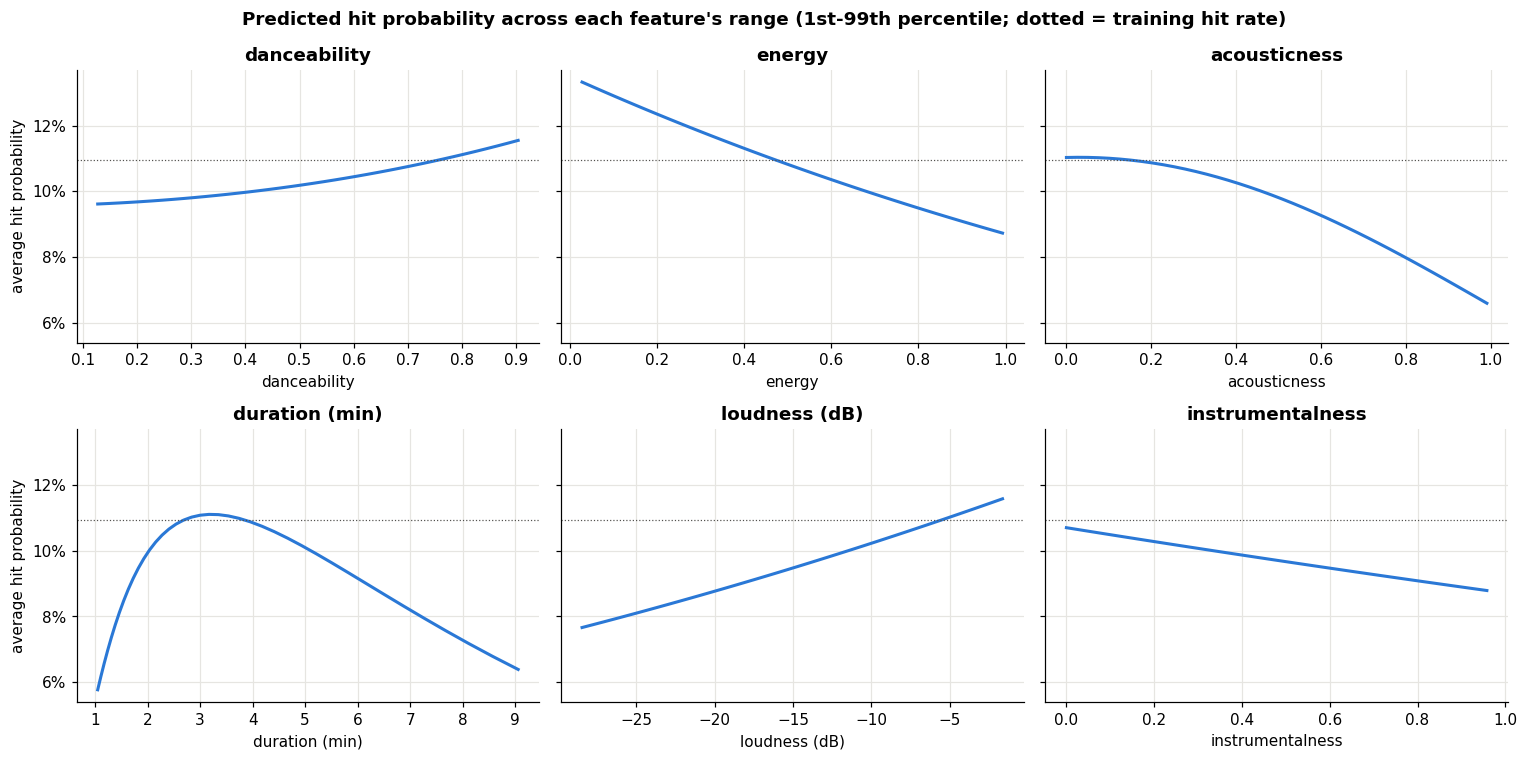

In [6]:
# effect curves: average predicted hit probability as one feature moves across its range, all else as observed
CURVES = [("danceability", "danceability"), ("energy", "energy"), ("acousticness", "acousticness"),
          ("log_duration", "duration (min)"), ("loudness", "loudness (dB)"), ("instrumentalness", "instrumentalness")]
mu, sd = train[AUDIO].mean(), train[AUDIO].std()
base = train.sample(5_000, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, (col, label) in zip(axes.flat, CURVES):
    lo, hi = train[col].quantile([0.01, 0.99])
    grid = np.linspace(lo, hi, 40)
    prob = [final.predict(base.assign(**{"z_" + col: (g - mu[col]) / sd[col]})).mean() for g in grid]
    x = 2 ** grid if col == "log_duration" else grid
    ax.plot(x, prob, color=BLUE, lw=2)
    ax.axhline(train["hit"].mean(), color=MUTED, lw=0.8, ls=":")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlabel(label); ax.set_title(label)
axes[0, 0].set_ylabel("average hit probability"); axes[1, 0].set_ylabel("average hit probability")
fig.suptitle("Predicted hit probability across each feature's range (1st-99th percentile; dotted = training hit rate)", fontweight="bold")
fig.tight_layout(); plt.savefig("figures/logit_03_effect_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# 6) Choosing the cut-off
The cut-off has to be chosen **without looking at the test set**; otherwise the test result is flattering. So:
1. 5-fold cross-validation on the training set, grouped by artist, gives an out-of-fold hit probability for every training song.
2. Several cut-off rules are compared on those out-of-fold probabilities.
3. The chosen cut-off is then applied once to the test set.

The cut-off rules:
- **Max F1:** the best balance of precision (share of pushed tracks that become hits) and recall (share of hits that get pushed).
- **Youden's J:** maximises true-positive rate minus false-positive rate. It treats a missed hit and a wasted push as equally bad, which pushes far too many tracks when hits are rare.
- **Cost-based break-even:** if pushing a track costs $C$ and a hit is worth $V$, pushing pays off on average whenever $p > C/V$. This needs calibrated probabilities, which logistic regression gives (section 6b). The table shows it for a few cost/value ratios.
- **Capacity:** push only the top $k$% of tracks, if the marketing budget fixes how many can be pushed.

out-of-fold AUC 0.890, average precision 0.533


,cutoff,share_pushed,precision,recall,lift,F1
rule,,,,,,
max F1,0.260,0.140,0.472,0.601,4.311,0.529
Youden's J,0.104,0.315,0.298,0.855,2.719,0.441
"break-even, cost/value = 0.20",0.200,0.186,0.410,0.697,3.751,0.517
"break-even, cost/value = 0.33",0.330,0.101,0.539,0.496,4.926,0.516
"break-even, cost/value = 0.50",0.500,0.052,0.642,0.305,5.865,0.414
capacity: top 5%,0.510,0.050,0.652,0.298,5.962,0.409
capacity: top 10%,0.331,0.100,0.540,0.494,4.939,0.516


chosen cut-off: push if P(hit) >= 0.26


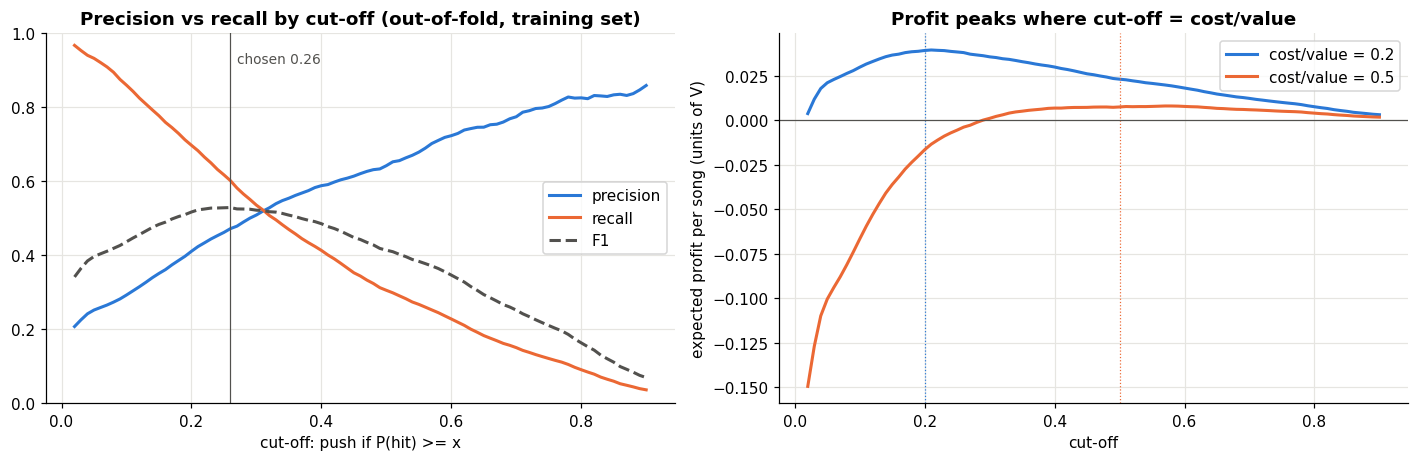

In [7]:
FINAL_F = FORMULAS["3. + genre (final)"]
oof = pd.Series(np.nan, index=train.index)
for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(train, groups=train["artist"])):
    # genre pooling was set on the full training set; refitting it per fold changes the folds very little
    oof.iloc[b] = fit_logit(FINAL_F, train.iloc[a], robust=False).predict(train.iloc[b]).values
y_tr = train["hit"]
print(f"out-of-fold AUC {roc_auc_score(y_tr, oof):.3f}, average precision {average_precision_score(y_tr, oof):.3f}")

def at_cutoff(y, p, c):
    push = p >= c
    tp = (push & (y == 1)).sum()
    prec = tp / max(push.sum(), 1)
    return {"cutoff": c, "share_pushed": push.mean(), "precision": prec, "recall": tp / (y == 1).sum(),
            "lift": prec / y.mean(), "F1": 2 * tp / (push.sum() + (y == 1).sum())}

cands = np.round(np.arange(0.02, 0.91, 0.01), 2)
curve = pd.DataFrame([at_cutoff(y_tr, oof, c) for c in cands])
fpr, tpr, thr = roc_curve(y_tr, oof)
rules = {"max F1": curve.loc[curve["F1"].idxmax(), "cutoff"],
         "Youden's J": thr[np.argmax(tpr - fpr)]}
for cv in [0.2, 0.33, 0.5]:
    rules[f"break-even, cost/value = {cv:.2f}"] = cv
for k in [0.05, 0.10]:
    rules[f"capacity: top {k:.0%}"] = oof.quantile(1 - k)
cut_tbl = pd.DataFrame([{"rule": r, **at_cutoff(y_tr, oof, c)} for r, c in rules.items()]).set_index("rule")
display(cut_tbl.round(3))
CUTOFF = float(rules["max F1"])
print(f"chosen cut-off: push if P(hit) >= {CUTOFF:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for col, c, ls in [("precision", BLUE, "-"), ("recall", ORANGE, "-"), ("F1", MUTED, "--")]:
    axes[0].plot(curve["cutoff"], curve[col], color=c, lw=2, ls=ls, label=col)
axes[0].axvline(CUTOFF, color=MUTED, lw=0.8)
axes[0].text(CUTOFF + 0.01, 0.95, f"chosen {CUTOFF:.2f}", color=MUTED, fontsize=9, va="top")
axes[0].set_xlabel("cut-off: push if P(hit) >= x"); axes[0].set_ylim(0, 1); axes[0].legend(loc="center right")
axes[0].set_title("Precision vs recall by cut-off (out-of-fold, training set)")
for cv, c in [(0.2, BLUE), (0.5, ORANGE)]:
    # expected profit per catalogue song, in units of V: hits pushed earn V, every push costs C
    profit = [((oof >= x) * (y_tr - cv)).mean() for x in cands]
    axes[1].plot(cands, profit, color=c, lw=2, label=f"cost/value = {cv}")
    axes[1].axvline(cv, color=c, lw=0.8, ls=":")
axes[1].axhline(0, color=MUTED, lw=0.8)
axes[1].set_xlabel("cut-off"); axes[1].set_ylabel("expected profit per song (units of V)"); axes[1].legend()
axes[1].set_title("Profit peaks where cut-off = cost/value")
fig.tight_layout(); plt.savefig("figures/logit_04_cutoff.png", dpi=150, bbox_inches="tight"); plt.show()

## 6b) Test set: the chosen cut-off on unseen artists, and probability calibration

,cutoff,share_pushed,precision,recall,lift,F1
set,,,,,,
test (unseen artists),0.26,0.124,0.489,0.528,4.258,0.508
train (out-of-fold),0.26,0.140,0.472,0.601,4.311,0.529


,not pushed,pushed
actual: not hit,12386,955
actual: hit,817,914


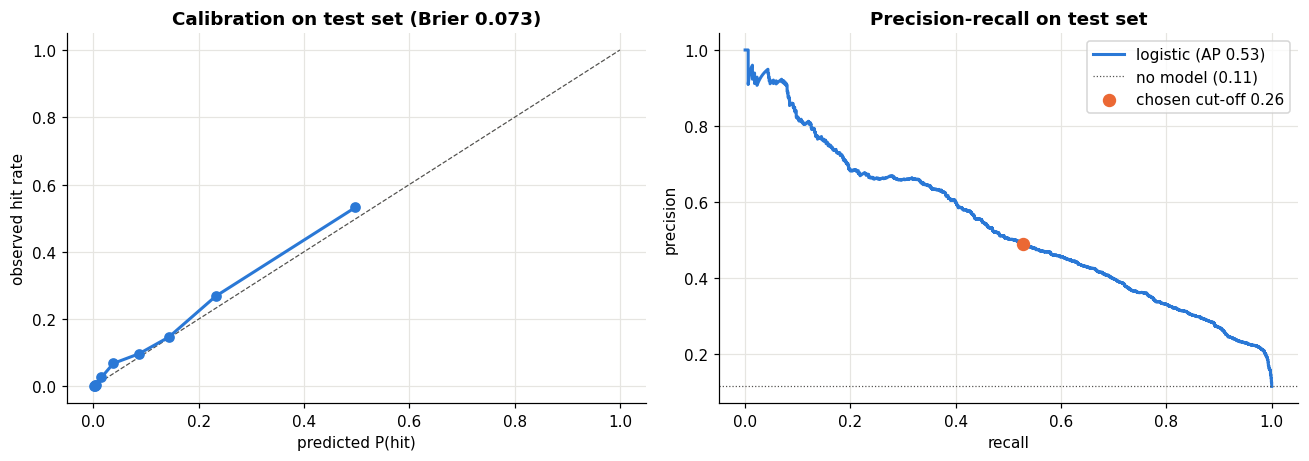

In [8]:
p_test = final.predict(test)
y_te = test["hit"]
test_res = pd.DataFrame([{"set": "test (unseen artists)", **at_cutoff(y_te, p_test, CUTOFF)},
                         {"set": "train (out-of-fold)", **at_cutoff(y_tr, oof, CUTOFF)}]).set_index("set")
display(test_res.round(3))
cm = pd.DataFrame(confusion_matrix(y_te, p_test >= CUTOFF), index=["actual: not hit", "actual: hit"],
                  columns=["not pushed", "pushed"])
display(cm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
frac, mean_p = calibration_curve(y_te, p_test, n_bins=10, strategy="quantile")
axes[0].plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls="--")
axes[0].plot(mean_p, frac, "o-", color=BLUE, lw=2)
axes[0].set_xlabel("predicted P(hit)"); axes[0].set_ylabel("observed hit rate")
axes[0].set_title(f"Calibration on test set (Brier {brier_score_loss(y_te, p_test):.3f})")
prec, rec, _ = precision_recall_curve(y_te, p_test)
axes[1].plot(rec, prec, color=BLUE, lw=2, label=f"logistic (AP {average_precision_score(y_te, p_test):.2f})")
axes[1].axhline(y_te.mean(), color=MUTED, lw=0.8, ls=":", label=f"no model ({y_te.mean():.2f})")
r = test_res.loc["test (unseen artists)"]
axes[1].scatter(r["recall"], r["precision"], color=ORANGE, s=60, zorder=3, label=f"chosen cut-off {CUTOFF:.2f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend(); axes[1].set_title("Precision-recall on test set")
fig.tight_layout(); plt.savefig("figures/logit_05_test_calibration_pr.png", dpi=150, bbox_inches="tight"); plt.show()

# 7) Robustness checks
Each check changes one choice and refits the final model. A robust result keeps a similar test performance and the same direction for the main odds ratios.
- **Hit definition:** top 5% and top 20% instead of top 10%.
- **Popularity-0 songs kept** (counted as non-hits).
- **No genre pooling:** every genre kept separate, fitted with an L2 penalty so the zero-hit genres don't diverge.

In [9]:
KEY = ["z_danceability", "z_energy", "z_loudness", "z_instrumentalness", "z_log_duration", "explicit", "collab", "is_4_4"]

def variant(name, q=HIT_Q, keep_zero=False):
    d = tracks[tracks["popularity"] >= (0 if keep_zero else 1)].reset_index(drop=True).copy()
    d["in_test_set"] = split(d)
    thr = d.loc[~d["in_test_set"], "popularity"].quantile(q)
    d["hit"] = (d["popularity"] >= thr).astype(int)
    d, genres, _ = build_features(d)
    f = "hit ~ " + BASE + SQ + INTER + " + " + " + ".join(genres)
    tr, te = d[~d["in_test_set"]], d[d["in_test_set"]]
    res = fit_logit(f, tr, robust=False)
    row = {"variant": name, "hit_threshold": thr, "hit_rate": te["hit"].mean(), **scores(te["hit"], res.predict(te))}
    return row, np.exp(res.params[KEY]).rename(name)

rows, ors = [], []
for args in [("top 10% (main)",), ("top 5%", 0.95), ("top 20%", 0.80), ("popularity-0 kept", HIT_Q, True)]:
    r, o = variant(*args); rows.append(r); ors.append(o)

# no pooling: every genre separate, L2-penalised (sklearn) so zero-hit genres stay finite
full = t.drop(columns=GENRES + ["g_pop"]).merge(GENRE_W, left_on="track_index", right_index=True)
all_g = [c for c in GENRE_W.columns if c != "g_pop"]
y, X = dmatrices("hit ~ " + BASE + SQ + INTER + " + " + " + ".join(all_g), full, return_type="dataframe")
trm = ~full["in_test_set"].values
l2 = LogisticRegression(C=1.0, max_iter=5000).fit(X[trm].drop(columns="Intercept"), y[trm].values.ravel())
p_l2 = l2.predict_proba(X[~trm].drop(columns="Intercept"))[:, 1]
rows.append({"variant": "no pooling, L2-penalised", "hit_threshold": HIT_THR, "hit_rate": y[~trm].values.mean(),
             **scores(y[~trm].values.ravel(), p_l2)})
ors.append(pd.Series(np.exp(l2.coef_[0]), index=X.columns.drop("Intercept"))[KEY].rename("no pooling, L2-penalised"))

display(pd.DataFrame(rows).set_index("variant").round(4))
or_tbl = pd.concat(ors, axis=1).rename(index=LABELS)
display(or_tbl.round(2))
same_dir = (np.sign(np.log(or_tbl)).nunique(axis=1) == 1)
print("odds ratios with the same direction in every variant:", ", ".join(or_tbl.index[same_dir]))
print("direction changes in:", ", ".join(or_tbl.index[~same_dir]) or "none")

,hit_threshold,hit_rate,test_AUC,test_avg_precision,test_Brier,test_log_loss
variant,,,,,,
top 10% (main),61.0,0.1148,0.8850,0.5332,0.0734,0.2407
top 5%,68.0,0.0494,0.9106,0.3805,0.0366,0.1304
top 20%,54.0,0.2140,0.8723,0.6515,0.1128,0.3486
popularity-0 kept,61.0,0.0979,0.8750,0.4325,0.0691,0.2293
"no pooling, L2-penalised",61.0,0.1148,0.8832,0.4939,0.0756,0.2459


,top 10% (main),top 5%,top 20%,popularity-0 kept,"no pooling, L2-penalised"
danceability,1.08,1.02,1.09,1.07,1.09
energy,0.82,0.94,0.84,0.82,0.78
loudness,1.13,1.10,1.05,1.14,1.17
instrumentalness,0.90,0.83,0.95,0.85,0.85
duration (log),0.94,1.01,0.87,0.94,0.93
explicit,1.52,1.57,1.34,1.53,1.49
collaboration,0.93,0.84,1.07,0.90,1.01
4/4 time,1.22,1.16,1.22,1.23,1.19


odds ratios with the same direction in every variant: danceability, energy, loudness, instrumentalness, explicit, 4/4 time
direction changes in: duration (log), collaboration


# 8) Outputs

In [10]:
# probability per song from the final model; train songs get an in-sample probability, test songs an out-of-sample one
t["hit_probability"] = final.predict(t).round(4)
t["push"] = t["hit_probability"] >= CUTOFF
out = t[["track_id", "track_name", "artists", "popularity", "hit", "hit_probability", "push", "in_test_set"]]
out.sort_values("hit_probability", ascending=False).to_csv("outputs/logit_predictions.csv", index=False)
print(f"saved outputs/logit_predictions.csv ({len(out):,} songs, {out['push'].mean():.1%} flagged to push) "
      "and outputs/logit_odds_ratios.csv")
display(out.sort_values("hit_probability", ascending=False).head(10))

saved outputs/logit_predictions.csv (76,585 songs, 13.6% flagged to push) and outputs/logit_odds_ratios.csv


,track_id,track_name,artists,popularity,hit,hit_probability,push,in_test_set
57910,3z06k8YF9CqX0CGFrlekOK,everything sucks,vaultboy,77,1,0.9818,True,False
57727,6PO6EnP2QoP4vN27KmKvrj,Nah They Can’t,Prem Dhillon,70,1,0.9807,True,False
57901,4TgxFMOn5yoESW6zCidCXL,Savage Love (Laxed – Siren Beat) [BTS Remix],Jawsh 685;Jason Derulo;BTS,73,1,0.9807,True,False
57805,7fBv7CLKzipRk6EC6TWHOB,The Hills,The Weeknd,88,1,0.9806,True,False
57846,1XGmzt0PVuFgQYYnV2It7A,Payphone,Maroon 5;Wiz Khalifa,84,1,0.9805,True,False
57810,4jPy3l0RUwlUI9T5XHBW2m,Mood (feat. iann dior),24kGoldn;iann dior,83,1,0.9805,True,False
57744,5QO79kh1waicV47BqGRL3g,Save Your Tears,The Weeknd,89,1,0.9801,True,False
57861,4ZtFanR9U6ndgddUvNcjcG,good 4 u,Olivia Rodrigo,88,1,0.9799,True,False
57937,4RULn5FlCuqIFSreEVp2Lb,Street Style,JERRY,63,1,0.9796,True,True
57751,4cluDES4hQEUhmXj6TXkSo,What Makes You Beautiful,One Direction,84,1,0.9792,True,True


# 9) Takeaways

## Is logistic regression suitable here?
**Yes, for the push decision, with the caveats below.** It answers the yes/no question directly, and on the same unseen-artist test songs it ranks hits better than the OLS score does: AUC 0.885 vs 0.849, and average precision 0.53 vs 0.47.

| | Assessment |
|---|---|
| Fits the decision | The output is a probability per song, which turns straight into a rule: push if P(hit) ≥ X. |
| Probabilities are reliable | The calibration curve sits close to the diagonal (Brier 0.073 vs 0.102 with no model). So a predicted 30% really means about 30%, which is what the cost-based rule $p > C/V$ needs. |
| Interpretable | Odds ratios show which features raise or lower the odds, with artist-clustered CIs. |
| Robust | Top 5% / 10% / 20% hit definitions, keeping popularity-0 songs, and an L2 model without genre pooling all give AUC 0.87–0.91. The main odds ratios keep their direction. |
| Loses information | Binarising treats a song at popularity 60 the same as one at 5. OLS keeps that detail; logistic gives it up in exchange for matching the decision. |
| Hit line is a choice | Top 10% is a business judgement. The results hold at 5% and 20%, but the cut-off X must be re-chosen if the definition changes. |
| Separation | Genres with almost no hits break an unpenalised fit. 38 of them are pooled, and the L2 check shows pooling does not drive the results. |
| Linear in log-odds | The squared terms capture the main curves. A tree model could find more interactions, at some cost to interpretability. |

## Which features make a hit more likely?
- **Genre matters most.** Genre alone reaches AUC 0.876, against 0.704 for all audio features and flags combined. Pop is the reference and has the highest hit odds; every other genre is below it, and the 38 pooled genres (e.g. study, black-metal, opera) almost never produce hits.
- **Within a genre (odds ratios, 95% CI excludes 1):**
  - raise the odds: **explicit** (1.52), **4/4 time** (1.22), **loudness** (1.13 per SD), **danceability** (1.08 per SD)
  - lower the odds: **energy** (0.82 per SD), **acousticness** (0.84), **instrumentalness** (0.90), **liveness** (0.93), and **non-music** tracks (0.11)
  - **duration** follows an inverted U, with the peak at about 3–3.5 minutes
- **Explicit holds up after controlling for genre** (OR 1.52), which answers the README's open robustness question. **Collaboration does not** (OR 0.93, not significant): its raw advantage in the EDA came from genre mix.
- **Energy reverses once genre is controlled for.** The EDA showed an inverted U across all songs, but within a genre more energy lowers the odds. The EDA pattern mostly reflected which genres are high-energy.
- Only danceability, energy, loudness, instrumentalness, explicit and 4/4 keep the same direction in every robustness check. Duration's main term and collaboration flip, so don't base decisions on them.

## What cut-off should we use?
**Push tracks with P(hit) ≥ 0.26.** This cut-off maximises F1 on out-of-fold training predictions. On unseen artists it:
- pushes 12.4% of tracks
- gets 49% of the pushed tracks right, 4.3× the 11.5% base rate
- catches 53% of all hits

Use a different rule when the business inputs are known:
- **Cost and value known:** push if $P(\text{hit}) \ge C/V$, the promotion cost divided by the value of a hit.
- **Fixed budget of $k$ pushes:** rank by probability and take the top $k$ (top 10% ≈ cut-off 0.33, precision 0.54).
- **Avoid Youden's J (0.10):** it pushes 31% of the catalogue at 30% precision, because it ignores that hits are rare.

## Limitations
- **Associations, not causes.** Popularity is measured *after* release, so it already includes past promotion and playlisting. Tracks that were pushed in the past look like "natural" hits, which can overstate how predictable success is.
- **No artist information.** Artist following is probably the largest missing driver. An out-of-fold artist feature is the obvious next step.
- **One snapshot** (around late 2022), with genres sampled at about 1,000 tracks each, so hit rates do not reflect Spotify's real catalogue.

**Outputs:**
- `outputs/logit_predictions.csv`: hit probability and push flag per song. Test-set rows are out-of-sample.
- `outputs/logit_odds_ratios.csv`: every coefficient with its odds ratio and CI.